In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("pd_speech_features.csv", header=1)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (756, 755)


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Columns: 755 entries, id to class
dtypes: float64(749), int64(6)
memory usage: 4.4 MB


In [ ]:
df.describe()

,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
count,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,...,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000
mean,125.500000,0.515873,0.746284,0.700414,0.489058,323.972222,322.678571,0.006360,0.000383,0.002324,...,26.237251,22.840337,18.587888,13.872018,12.218953,12.375335,14.799230,14.751559,31.481110,0.746032
std,72.793721,0.500079,0.169294,0.069718,0.137442,99.219059,99.402499,0.001826,0.000728,0.002628,...,42.220693,32.626464,25.537464,20.046029,17.783642,16.341665,15.722502,14.432979,34.230991,0.435568
min,0.000000,0.000000,0.041551,0.543500,0.154300,2.000000,1.000000,0.002107,0.000011,0.000210,...,1.509800,1.531700,1.582900,1.747200,1.789500,1.628700,1.861700,1.955900,2.364000,0.000000
25%,62.750000,0.000000,0.762833,0.647053,0.386537,251.000000,250.000000,0.005003,0.000049,0.000970,...,2.408675,3.452800,3.354825,3.077450,2.937025,3.114375,3.665925,3.741275,3.948750,0.000000
50%,125.500000,1.000000,0.809655,0.700525,0.484355,317.000000,316.000000,0.006048,0.000077,0.001495,...,5.586300,7.062750,6.077400,4.770850,4.300450,4.741450,6.725700,7.334250,10.637250,1.000000
75%,188.250000,1.000000,0.834315,0.754985,0.586515,384.250000,383.250000,0.007528,0.000171,0.002520,...,28.958075,29.830850,21.944050,13.188000,10.876150,12.201325,21.922050,22.495175,61.125325,1.000000
max,251.000000,1.000000,0.907660,0.852640,0.871230,907.000000,905.000000,0.012966,0.003483,0.027750,...,239.788800,203.311300,121.542900,102.207000,85.571700,73.532200,62.007300,57.544300,156.423700,1.000000


The first step was to download the data from the UC Irvine Machine Learning Repository. Because I have a mac I had to download the "unarchiver" from the app store. Once this was downloaded I was able to upload the file to google collab.

Overall, the output shows that the dataset has 756 voice recordings. More specifically, there are 756 rows and 755 columns. However, from the table above I see that the miniumum values are 0 and it ranges to 251. So I am estimated that the number of participants are approximately 250. The next step in the process to is examine how many participants are in the data set.

In [ ]:
# Check the number of unique participants
print("Total recordings:", len(df))
print("Unique participants:", df["id"].nunique())

# Examine how many recordings each participant contributed
print("\nRecordings per participant:")
print(df.groupby("id").size().value_counts().sort_index())

Total recordings: 756
Unique participants: 252

Recordings per participant:
3    252
Name: count, dtype: int64


Part 1. Understand the data.

1. What is the unit of observation here, and what is the unit of independence? What does that imply for how you may split the data?

The findings reveal that there are a total of 756 total recordings and a total of 252 unique participants. In addition to this, there are three recordings per participant. So although the dataset has 756 observations, these observations are not entirely independent because there are some participants with multiple recordings. This distinction is important when splitting the data into the training and testing sets to prevent data leakage. In answering the question, the unit of observation is the individual voice recordings of 756, the unit of independence is each individual participant (252), and the implications for splitting is that all three recordings from the same participant must remain together in either the training or testing dataset to prevent the data leakage.


2. What accuracy does the majority-class baseline get? Which metrics will you report instead, and why? Name the modeling decision your visualization motivates?



In [ ]:
#The next step in the process is to examine the class balance. An imbalanced dataset can affect how we evaluate our machine learning models.

# Examine the outcome variable
print("Classification counts:")
print(df["class"].value_counts())

# Calculate percentages
print("\nClassification percentages:")
print(df["class"].value_counts(normalize=True) * 100)

# Examine unique participants by classification
print("\nUnique participants by classification:")
print(df.groupby("class")["id"].nunique())

Classification counts:
class
1    564
0    192
Name: count, dtype: int64

Classification percentages:
class
1    74.603175
0    25.396825
Name: proportion, dtype: float64

Unique participants by classification:
class
0     64
1    188
Name: id, dtype: int64


The findings reveals that the dataset has a class imbalance. More specifically, approximately three-quarters of participants have Parkinson's disease. This matters because a machine larning model could predict Parkinson's disease for every participant and still achieve 74.6% accuracy. Because of this, in the current analyses, this supports using ROC AUC, senssitivity, and specifictiy rather than relying on accuracy alone.


The next step is to determine what 0 and 1 means. I know that in the instructions it is noted, I just wanted to see if it was assigned labels in the data. If not, the next step in the process is to create labels.

In [ ]:
# Identify the values assigned to the outcome variable
print("Unique classification values:")
print(df["class"].unique())

# Examine how many recordings belong to each category
print("\nClassification counts:")
print(df["class"].value_counts())

Unique classification values:
[1 0]

Classification counts:
class
1    564
0    192
Name: count, dtype: int64


In [ ]:
# Assign descriptive labels to classification values
df["class_label"] = df["class"].map({
    0: "Healthy",
    1: "Parkinson's Disease"
})

# Check the labeled distribution
print(df["class_label"].value_counts())

class_label
Parkinson's Disease    564
Healthy                192
Name: count, dtype: int64


In the output above, 1 = Parkinson's disease (564) and 0 = Healthy participants (192).

In [ ]:
# Check missing values
print("Total missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Total missing values: 0
Duplicate rows: 1


Based on the small amount of data missing, I will not use imputation to address the missing data. The next step is to identify the duplicate rows.

In [ ]:
# Identify the duplicate observations
duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows)

# Examine the participant IDs
print("Participant IDs with duplicate rows:")
print(duplicate_rows["id"].unique())

,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class,class_label
111,37,0,0.79067,0.58465,0.6425,321,320,0.006004,0.000143,0.00207,...,4.0251,2.9654,3.8369,4.2973,3.6458,3.1854,3.7708,10.0693,1,Parkinson's Disease
113,37,0,0.79067,0.58465,0.6425,321,320,0.006004,0.000143,0.00207,...,4.0251,2.9654,3.8369,4.2973,3.6458,3.1854,3.7708,10.0693,1,Parkinson's Disease


Participant IDs with duplicate rows:
[37]


The findings revealed two duplicate rows. It looks like participant 37 how two entries. Because the dataset includes three recordings per participants, the duplicate was retained. I would like to determine if it was a duplicate or part of the three recordings as the findings suggested earlier. To reduce the risk of data leakage, all recordings belonging to the same participant will be kept together during the model validation.

In [ ]:
# Examine all recordings for Participant 37
participant_37 = df[df["id"] == 37]

print("Number of recordings:", len(participant_37))

display(participant_37[[
    "id", "gender", "PPE", "DFA", "RPDE", "class"
]])

Number of recordings: 3


,id,gender,PPE,DFA,RPDE,class
111,37,0,0.79067,0.58465,0.64250,1
112,37,0,0.75781,0.57600,0.65037,1
113,37,0,0.79067,0.58465,0.64250,1


The next step in the process is to chose the model visualization. I would like to use a bar chart to show the class imbalance.

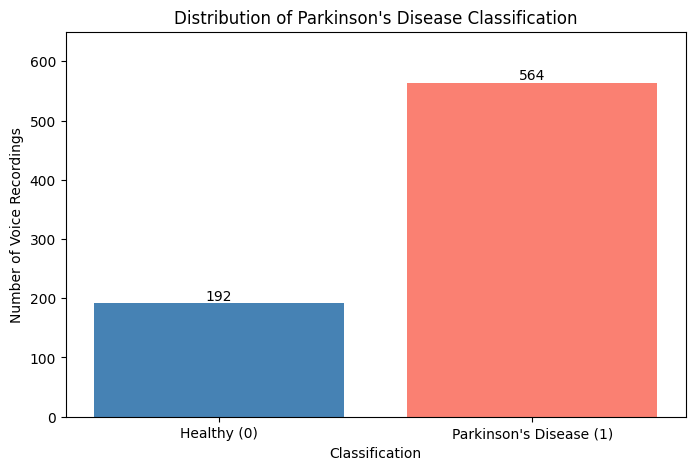

In [ ]:
# Visualize class imbalance in the Parkinson's dataset
class_counts = df["class"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Healthy (0)", "Parkinson's Disease (1)"],
    class_counts.values,
    color=["steelblue", "salmon"]
)

# Add frequency labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 5,
        f"{int(height)}",
        ha="center"
    )

plt.title("Distribution of Parkinson's Disease Classification")
plt.xlabel("Classification")
plt.ylabel("Number of Voice Recordings")
plt.ylim(0, 650)
plt.show()

The bar chart indicates that 564 (74.6%) of the recordings belong to the Parkinson's disease classification compared to 25.4% (n = 192) from healthy participants. The majority-class baselline accuracy is 0.746, suggesting that accuracy alone may be misleading when evaluating model performance. I would instead report ROC AUC, sensitivity, and specificity to assess how effectivelty the model distinguishes between the two groups, particulary the ability to identify person with Parkinson's disease. Because of the class imbalance shown in the bar chart, I would also compare models with and without class weighting to determine whether balancing the classes during training improves classification performance.

Task: Hold out about 20% of subjects as a test set (stratified, grouped by subject) and show there is zero subject overlap. On the training portion, compare 5-fold CV AUC for a scaled logistic regression and a random forest using (a) StratifiedKFold and (b) StratifiedGroupKFold. Write your prediction in a markdown cell before you run it. Then repeat the grouped, stratified CV for the logistic regression with k = 3, 5 and 10, and report the mean and standard deviation of the fold AUCs.

Part 2. Splitting and Leakage

3.  Report all four AUCs. Explain, step by step, why the two splitters disagree. Which estimate would you report, and what goes wrong if you report the other?

4. (a) Why use StratifiedGroupKFold rather than plain GroupKFold here? Use the class balance and the number of subjects. (b) Would leave-one-out CV be valid on these recordings? If not, what is the valid version?

5. How did the mean and standard deviation change as k went from 3 to 10? Explain the trade-off with only 252 subjects, and say which k you would use.

In [ ]:
from sklearn.model_selection import train_test_split

# Separate predictors from the outcome and subject identifiers.
# Subject IDs will be used for grouping, not as predictors.
X = df.drop(columns=["class", "id", "class_label"], errors="ignore")
y = df["class"]
groups = df["id"]

# Create one record per participant for a stratified subject-level split.
subjects = df.groupby("id")["class"].first()

train_ids, test_ids = train_test_split(
    subjects.index,
    test_size=0.20,
    stratify=subjects.values,
    random_state=42
)

# Keep all recordings from each participant in the same partition.
train_mask = groups.isin(train_ids)
test_mask = groups.isin(test_ids)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

groups_train = groups.loc[train_mask]
groups_test = groups.loc[test_mask]

print("Training recordings:", len(X_train))
print("Testing recordings:", len(X_test))

print("\nTraining participants:", groups_train.nunique())
print("Testing participants:", groups_test.nunique())

# Verify no participant occurs in both datasets.
overlap = set(groups_train).intersection(set(groups_test))

print("\nOverlapping participant IDs:", len(overlap))

# Verify class distributions in both partitions.
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training recordings: 603
Testing recordings: 153

Training participants: 201
Testing participants: 51

Overlapping participant IDs: 0

Training class proportions:
class
1    0.746
0    0.254
Name: proportion, dtype: float64

Testing class proportions:
class
1    0.745
0    0.255
Name: proportion, dtype: float64


These findings indicate the 201 particiants are in the training set and 51 in the testing set. With regards to voice recordings 603 are in the training and 153 are in the testing. The proportion of individuals with Parkinson's disease is almost identical, 74.6% and 74.5%, respectively. There are no overlapping participant id's. Overall, this reduces the risk of data leakage from repeated recordings.

The next step in the process is to compare two cross-validation methods.

In terms of hypothesis testing, I predict that the

The next step in the process is to compare two cross-validation methods.

In terms of hypothesis testing, I predict that the StratifiedKFold will produce higher ROC AUC socres than StratifiedGroupKFold for both logistic regression and random forest. Because StratifiedKFold does not account for repeated recordings from the same participants, information about individuals may be represented in both the training and validation folds, potentially inflating performance estimates. In contrast StratifiedGroupKFold will keepp participants in separate folds.

In learning more about StratifiedKFold in comparison to StratifiedGroupKFold, is that the StratifiedKFold just divides the recordings without recognizing that three recordings may come from the same person. StratifiedGroupKFold recognizes that recordings belong to the participants.

In [ ]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Define the two cross-validation approaches
skf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

sgkf = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

# Scaling occurs within each training fold to prevent leakage.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Compare ROC AUC using training data only.
for name, model in [
    ("Logistic Regression", logistic_model),
    ("Random Forest", rf_model)
]:
    regular_scores = cross_val_score(
        model, X_train, y_train,
        cv=skf, scoring="roc_auc"
    )

    grouped_scores = cross_val_score(
        model, X_train, y_train,
        groups=groups_train,
        cv=sgkf, scoring="roc_auc"
    )

    print(f"\n{name}")
    print(f"StratifiedKFold AUC: {regular_scores.mean():.3f}")
    print(f"StratifiedGroupKFold AUC: {grouped_scores.mean():.3f}")


Logistic Regression
StratifiedKFold AUC: 0.878
StratifiedGroupKFold AUC: 0.816

Random Forest
StratifiedKFold AUC: 0.953
StratifiedGroupKFold AUC: 0.857


The findings reveal that both models, the logistic regression andthe random forest performed better in the StratifiedKFold. More specifically, the logistic regression achieved an ROC AUC of .878 using StratifiedKFold compared to .816 using StratifiedGroupKFold. This was the same result for the random forest that achieved an AUC of .953 using StratifiedKFold and .857 using StratifiedGroupKFold. The higher AUC values under StratifiedKFold may reflect data leadkage becasue recorings from the same participants can appear in both training and validiation folds, potentially inflating predicitive performance. I would reported the StratifiedGroupKFold estimate because they keep each participants recordings together and provide a more realistic assessment of how the models perform on new participants.

The next step is repeating  using 3, 5, and 10 folds and to calculate the mean and sd of AUC.

In [ ]:
# Compare the stability of grouped cross-validation
# using 3, 5, and 10 folds.

for k in [3, 5, 10]:
    cv = StratifiedGroupKFold(
        n_splits=k,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        logistic_model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring="roc_auc"
    )

    print(f"\n{k}-Fold StratifiedGroupKFold")
    print(f"Mean AUC: {scores.mean():.3f}")
    print(f"Standard Deviation: {scores.std():.3f}")


3-Fold StratifiedGroupKFold
Mean AUC: 0.832
Standard Deviation: 0.048

5-Fold StratifiedGroupKFold
Mean AUC: 0.816
Standard Deviation: 0.070

10-Fold StratifiedGroupKFold
Mean AUC: 0.800
Standard Deviation: 0.066


The findings revealed that the highest average AUC was using three folds at .832. It also had the lowest sd of .048, suggesting that performance varied less across the three validation groups. However, under the five fold the AUC decreased slightly and the sd increased to .070. This suggests that the model's performance varied more across the five validation groups in comparison to the three validation groups. The last model, the ten fold had the lowest AUC at .800 and the a sd of .066. This suggests that each validation fold contained fewer individuals. I would selected the 5 fold StratifiedGroupKFold because it provides a balance between training and validation sample sizes while maintaining separation between participants.

Also, I would use StratifiedGroupKFold rather than GroupKFold because the dataset contains an unequal distribution of participants with 188 diagnosed with Parkinson's disease and 64 classified as healthy. StratifiedGroupKFold attempts to maintain similar proportions of both classification across folds while ensuring that recordngs from the same person remain together. Traditional leave one recording out cross validation would not be appropriate because recordings from the same participant could appear in both training and validation datasets, creating data leakage. A more appropriate alternative would be leave one subject out cross valiation, where all three of the recordings from one person are held out together for validation.

Part 3. Leakage inside the pipeline

Create 500 columns of pure random noise for the same rows. (a) Select the top 20 noise features with SelectKBest on all the data, then cross-validate a logistic regression with grouped, stratified folds. (b) Repeat with the selection step inside a Pipeline. (c) Build the correct pipeline for the real features.

6.  What AUC should a model get on pure noise? Report your results for (a) and (b), and explain exactly where information leaked in (a).

7.  Name two other preprocessing steps from this course that carry the same risk. For each, say where it must sit relative to the CV split.

The first step in the problem is to create 500 columns.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedGroupKFold

# Generate reproducible random noise with no true
# relationship to Parkinson's disease.
rng = np.random.default_rng(42)

X_noise = pd.DataFrame(
    rng.normal(size=(len(X_train), 500)),
    index=X_train.index,
    columns=[f"noise_{i}" for i in range(500)]
)

print("Noise dataset shape:", X_noise.shape)
display(X_noise.head())

Noise dataset shape: (603, 500)


,noise_0,noise_1,noise_2,noise_3,noise_4,noise_5,noise_6,noise_7,noise_8,noise_9,...,noise_490,noise_491,noise_492,noise_493,noise_494,noise_495,noise_496,noise_497,noise_498,noise_499
0,0.304717,-1.039984,0.750451,0.940565,-1.951035,-1.302180,0.127840,-0.316243,-0.016801,-0.853044,...,1.085287,0.366531,-0.286249,0.453966,-0.308673,0.935547,-1.831406,-0.335607,-1.990812,-1.495061
1,1.363862,0.895185,-0.719480,-1.502503,-2.964529,-0.543496,2.420415,0.434884,-0.559572,0.465080,...,0.870556,1.479275,1.794370,1.314808,-0.109734,0.352720,0.766823,0.121178,0.130764,0.823753
2,-0.059283,-0.729287,-0.414473,0.633910,0.002993,0.340210,0.670079,-0.374841,0.756248,0.378843,...,-0.616293,-0.022685,-0.622540,-1.071701,-0.353615,-1.103989,0.322797,-1.150085,0.711977,-1.181479
6,-0.566295,-0.624603,1.325147,0.330290,-0.211734,0.498719,-2.107192,-0.043134,1.997514,0.132347,...,0.390725,0.545323,0.231660,0.965170,0.087868,0.392011,0.303837,-0.091540,-0.530822,2.214153
7,-0.451951,-0.665878,0.434010,0.251854,-1.404792,1.122678,-0.094195,-1.110931,1.188784,0.625676,...,0.815316,-0.701767,0.765955,-0.761992,1.090660,2.210641,-0.122084,-2.192543,-0.548073,1.231875


These findings reveal that there are 600 rows and 500 columns. The 600 rows are voice recordings in the training dataset and the 500 columns are the randomly generated variables that contain really no information about Parkinson's disease.

In [ ]:
# Experiment A: Feature selection BEFORE cross-validation introducing the leakage.

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Select the top 20 features using ALL training observations.
# This is intentionally incorrect because validation labels
# influence feature selection.
selector = SelectKBest(score_func=f_classif, k=20)

X_noise_selected = selector.fit_transform(X_noise, y_train)

print("Selected noise feature shape:", X_noise_selected.shape)

# Grouped cross-validation still prevents participant overlap,
# but it cannot undo leakage from earlier feature selection.
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)

leaky_scores = cross_val_score(
    model,
    X_noise_selected,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring="roc_auc"
)

print("\nExperiment A: Feature Selection Before CV")
print("Fold AUCs:", np.round(leaky_scores, 3))
print(f"Mean AUC: {leaky_scores.mean():.3f}")
print(f"Standard Deviation: {leaky_scores.std():.3f}")

Selected noise feature shape: (603, 20)

Experiment A: Feature Selection Before CV
Fold AUCs: [0.791 0.817 0.691 0.739 0.765]
Mean AUC: 0.761
Standard Deviation: 0.043


The mean AUC is .761 and the sd is .043. Although this might appear as a good model, the problem was that I selected the 20 best performing variables before cross-validation. This leads to data leakage which can make the model look more predictive than it really is. In other words, information from the validation observations influenced feature selection.

The next step in the process is to correct for this.

In [ ]:
# Experiment B: Feature selection INSIDE cross-validation, preventing validation data from influencing feature selection.

correct_pipeline = make_pipeline(
    SelectKBest(score_func=f_classif, k=20),
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)

correct_scores = cross_val_score(
    correct_pipeline,
    X_noise,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring="roc_auc"
)

print("Experiment B: Feature Selection Inside Pipeline")
print("Fold AUCs:", np.round(correct_scores, 3))
print(f"Mean AUC: {correct_scores.mean():.3f}")
print(f"Standard Deviation: {correct_scores.std():.3f}")

Experiment B: Feature Selection Inside Pipeline
Fold AUCs: [0.614 0.583 0.538 0.534 0.555]
Mean AUC: 0.565
Standard Deviation: 0.030


These findings are different from the experiment a (first model). The mean AUC is not .565 with a sd of .030. Once I corrected form the feature selection procedure. In experiment a, selecting the top 20 featues before cross-validation is misleading and produced a mean AUC of .761 (sd = .043) in comparison to placing feature selection inside the pipeline in experiment b, which reduced the mean AUC to .565 (sd = .030). Data leakage occured in experiment a because all 603 training observations used for validation influenced the selection of features. These findings demonstrate that conducting feature selection before cross-validation can inflate estimates of predictive performance.

The final step is the build the correct pipeline for the real features.

In [ ]:
# Construct a leakage-free pipeline using real acoustic features.
# Feature selection and scaling are fitted separately within each CV training fold.

real_pipeline = make_pipeline(
    SelectKBest(score_func=f_classif, k=20),
    StandardScaler(),
    LogisticRegression(
        max_iter=5000,
        random_state=42
    )
)

real_scores = cross_val_score(
    real_pipeline,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring="roc_auc"
)

print("Real Parkinson's Disease Features")
print("Fold AUCs:", np.round(real_scores, 3))
print(f"Mean AUC: {real_scores.mean():.3f}")
print(f"Standard Deviation: {real_scores.std():.3f}")

Real Parkinson's Disease Features
Fold AUCs: [0.804 0.895 0.833 0.79  0.681]
Mean AUC: 0.801
Standard Deviation: 0.070


The findings revealed that a mean AUC of .801 that suggest meaningful dicrimination between Parkinson's disease and healthy participants. In comparing all three experiments, by using actural acoustic features, the logistic regression pipeline achieved the best AUC of .801 (sd = .070) across five group, stratified folds. This was higher than the AUC of .565 obtained using the random noise with proper feature selection. However, the AUC was slightly lower than the earlier logistic regression model that used all features. These findings suggest that selecting only 20 features did not improve predictive performance in the analysis.

The next step in the process is to name two other preprocessing steps from our current course that carry the same risk.

1. I would say that feature scaling can carry the same risk. For example, when we standardize variables, we calculate the means and sd's. If we calculate these statistics using the entire dataset before cross-validation, information from the validation fold influences the transformation.

2. There can also be some issues with the missing-data imputation that can introduce leakage when replacemet values are estimated using the entire dataset before cross-validation. Basically, when we replace missing values with an estiamted values, we have to calcuate that estimate using onthe training fold. If we don't, the validation fold contributes information to the imputation procedure.






Part 4. Bias, variance and regularization

With a scaler plus L2 logistic regression pipeline, sweep C on a log scale (at least 8 values from 1e-5 to 10). Plot training AUC and CV AUC against C. At a good C, plot a learning curve using grouped, stratified CV. Compare L1, L2 and Elastic Net at a good C: the number of non-zero coefficients and the CV AUC. For the L2 model, report the three largest coefficients as odds ratios (the features are standardized).


8. Mark the underfitting and overfitting regions on your C plot. At C = 1, what does the gap between training and CV AUC tell you? Use bias and variance language. From your learning curve, would more subjects help, or is something else the limit?

9. Why does strong regularization help when features outnumber recordings? Why should you not over-interpret which features L1 keeps? Interpret one odds ratio in a sentence, and say what it does not tell you.

In [ ]:
from sklearn.model_selection import cross_validate, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Test 10 values of C on a logarithmic scale.
# Smaller C values impose stronger regularization.
C_values = np.logspace(-5, 1, 10)

cv_part4 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for C in C_values:

    # Scaling is fitted separately within each training fold
    # to prevent information leakage.
    pipeline = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            C=C,
            max_iter=5000,
            random_state=42
        )
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv_part4,
        scoring="roc_auc",
        return_train_score=True
    )

    results.append({
        "C": C,
        "Training_AUC": scores["train_score"].mean(),
        "CV_AUC": scores["test_score"].mean(),
        "CV_SD": scores["test_score"].std()
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,C,Training_AUC,CV_AUC,CV_SD
0,0.000,0.848,0.820,0.047
1,0.000,0.855,0.824,0.049
2,0.000,0.876,0.834,0.052
3,0.001,0.918,0.850,0.058
4,0.005,0.971,0.857,0.066
5,0.022,0.998,0.847,0.069
6,0.100,1.000,0.830,0.071
7,0.464,1.000,0.819,0.071
8,2.154,1.000,0.814,0.071
9,10.000,1.000,0.805,0.073


The findings reveal that the highest cross-validation AUC occurs at .005 and the highest mean AUC is .857.

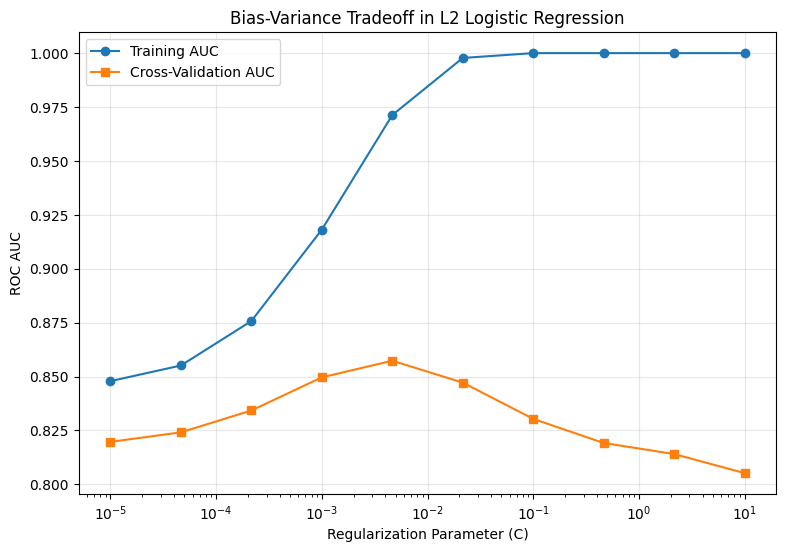

In [ ]:
# Compare training and cross-validation performance
# across different regularization strengths.

plt.figure(figsize=(9, 6))

plt.semilogx(
    results_df["C"],
    results_df["Training_AUC"],
    marker="o",
    label="Training AUC"
)

plt.semilogx(
    results_df["C"],
    results_df["CV_AUC"],
    marker="s",
    label="Cross-Validation AUC"
)

plt.xlabel("Regularization Parameter (C)")
plt.ylabel("ROC AUC")
plt.title("Bias-Variance Tradeoff in L2 Logistic Regression")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The training AUC continues increasing while the validation AUC peaks and then declines.

Overall, the results suggest a bias-variance trade-off across different levels of L2 regularization. In the above table, the highest cross-validation ROC AUC was .857 at approximately C = .005, suggesting that strong regularization improved generalization. At larger C values, training AUC reached 1.000 while cross-validation AUC declined, indicating overfitting and increased variance. Strong regularization at very small C values may also limit ppredictive performance by introducing more bias.

In [ ]:
# Evaluate C = 1 specifically for Question 8

model_c1 = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l2",
        C=1,
        max_iter=5000,
        random_state=42
    )
)

scores_c1 = cross_validate(
    model_c1,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv_part4,
    scoring="roc_auc",
    return_train_score=True
)

train_auc_c1 = scores_c1["train_score"].mean()
cv_auc_c1 = scores_c1["test_score"].mean()

print(f"Training AUC at C=1: {train_auc_c1:.3f}")
print(f"CV AUC at C=1: {cv_auc_c1:.3f}")
print(f"Training-CV gap: {train_auc_c1 - cv_auc_c1:.3f}")

Training AUC at C=1: 1.000
CV AUC at C=1: 0.816
Training-CV gap: 0.184


The findings reveal that at C = 1, the logistic regression model achieved a training AUC of 1.000 and a cross-validtion AUC of .816, resulting in a gap of .184. The difference suggest overfitting, where the model performs extremely well on the training data but demonstrates weaker generalization to new participants. In terms of the bias and variance, the model shows low training error but high variance because it may be capturing patterns specific only to the training data. Stronger regularization such as C = .005 and produced a higher cross-validation AUC of .857 indicating a better balance between the model complexity and generalization.

The next step in the process is generating a learning curve.

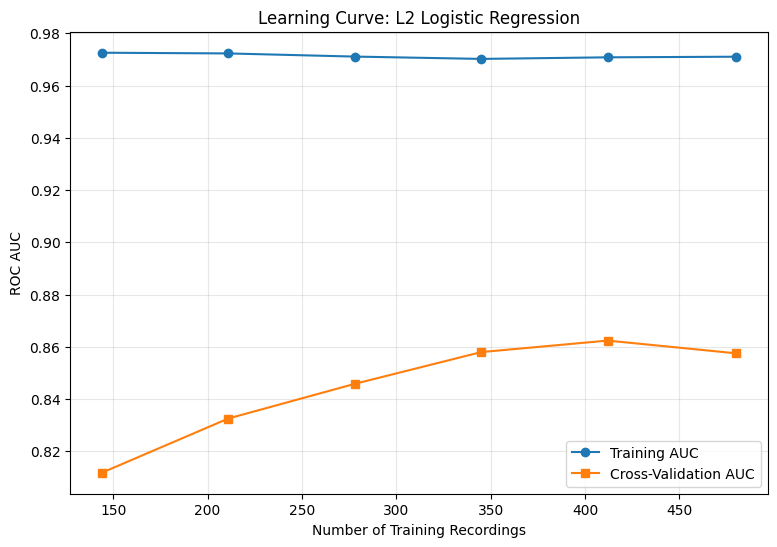

Training sizes: [144 211 278 345 412 480]
Training AUC: [0.973 0.972 0.971 0.97  0.971 0.971]
Validation AUC: [0.812 0.833 0.846 0.858 0.862 0.858]


In [ ]:
from sklearn.model_selection import learning_curve
from sklearn.base import clone

# Use the C value with the highest observed CV AUC.
best_C = results_df.loc[results_df["CV_AUC"].idxmax(), "C"]

learning_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l2",
        C=best_C,
        max_iter=5000,
        random_state=42
    )
)

# Grouped CV preserves independence between participants.
# Fractional sizes are based on recordings, so we will
# inspect how many distinct subjects are actually used.
train_sizes, train_scores, val_scores = learning_curve(
    estimator=learning_model,
    X=X_train,
    y=y_train,
    groups=groups_train,
    cv=cv_part4,
    train_sizes=np.linspace(0.3, 1.0, 6),
    scoring="roc_auc",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training AUC"
)

plt.plot(
    train_sizes,
    val_mean,
    marker="s",
    label="Cross-Validation AUC"
)

plt.xlabel("Number of Training Recordings")
plt.ylabel("ROC AUC")
plt.title("Learning Curve: L2 Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Training sizes:", train_sizes)
print("Training AUC:", np.round(train_mean, 3))
print("Validation AUC:", np.round(val_mean, 3))

These findings revealed that adding more participants could potentially improve the model performance. The training data remains consistently high, however the cross-validation AUC increases approximately .812 to to .858.

The regularization analysis indicated that very small C values were associated with greater bias and potential underfitting, while larger C values demonstrated increased overfitting. At C = 1, the training AUC was 1.000 compared to a cross-validation AUC of .816, producing a gap of .184 that suggest high variance and reduced genderalization. The learning curve also tells us that cross-validation AUC increased from approximately .812 to .858 as the amount of training data increased, while training AUC remained near .970. The findings suggest that additional participants may improve the generalizastion, although the remaining gap indicate that model complexity and feature quality may also limit model performance.

In [ ]:
# Compare regularization methods at the best observed C value

from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

best_C = results_df.loc[results_df["CV_AUC"].idxmax(), "C"]

models = {
    "L1": LogisticRegression(
        penalty="l1", solver="saga", C=best_C,
        max_iter=10000, random_state=42
    ),
    "L2": LogisticRegression(
        penalty="l2", solver="saga", C=best_C,
        max_iter=10000, random_state=42
    ),
    "Elastic Net": LogisticRegression(
        penalty="elasticnet", solver="saga",
        l1_ratio=0.5, C=best_C,
        max_iter=10000, random_state=42
    )
}

comparison = []

for name, model in models.items():

    pipeline = make_pipeline(StandardScaler(), model)

    scores = cross_val_score(
        pipeline, X_train, y_train,
        groups=groups_train,
        cv=cv_part4,
        scoring="roc_auc"
    )

    # Fit on training data only to examine coefficients
    pipeline.fit(X_train, y_train)

    coefficients = pipeline.named_steps["logisticregression"].coef_[0]
    nonzero = np.sum(np.abs(coefficients) > 1e-6)

    comparison.append({
        "Method": name,
        "Nonzero_Coefficients": nonzero,
        "Mean_CV_AUC": scores.mean(),
        "CV_SD": scores.std()
    })

display(pd.DataFrame(comparison).round(3))

,Method,Nonzero_Coefficients,Mean_CV_AUC,CV_SD
0,L1,0,0.500,0.000
1,L2,753,0.857,0.067
2,Elastic Net,2,0.500,0.000


The results suggest that at L1 eliminated all 753 predicotrs, indicating no useful distinction between Parkinson's disease and healthly participants (AUC = .500). L2 retained all 753 predictors with a mean AUC of .857 and sd of .06. The Elastic Net kept only 2 predictors and the cross-validation was .500.


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

# Explore different levels of regularization.
C_values = [0.001, 0.01, 0.1, 1, 10]

penalties = {
    "L1": {"penalty": "l1", "l1_ratio": None},
    "L2": {"penalty": "l2", "l1_ratio": None},
    "Elastic Net": {"penalty": "elasticnet", "l1_ratio": 0.5}
}

results_regularization = []

for name, settings in penalties.items():

    for C in C_values:

        model = LogisticRegression(
            penalty=settings["penalty"],
            l1_ratio=settings["l1_ratio"],
            solver="saga",
            C=C,
            max_iter=10000,
            tol=1e-3,
            random_state=42
        )

        pipeline = make_pipeline(
            StandardScaler(),
            model
        )

        scores = cross_val_score(
            pipeline,
            X_train,
            y_train,
            groups=groups_train,
            cv=cv_part4,
            scoring="roc_auc"
        )

        results_regularization.append({
            "Method": name,
            "C": C,
            "Mean_CV_AUC": scores.mean(),
            "CV_SD": scores.std()
        })

regularization_df = pd.DataFrame(results_regularization)

display(regularization_df.round(3))

,Method,C,Mean_CV_AUC,CV_SD
0,L1,0.001,0.500,0.000
1,L1,0.010,0.532,0.065
2,L1,0.100,0.870,0.051
3,L1,1.000,0.834,0.066
4,L1,10.000,0.824,0.075
5,L2,0.001,0.847,0.058
6,L2,0.010,0.851,0.072
7,L2,0.100,0.834,0.077
8,L2,1.000,0.824,0.075
9,L2,10.000,0.822,0.076


L1 has the highest cross-validation AUC of the three approaches. (C = 0.100) and the mean AUC is .870. increasing C from .001 to .100 improved it from .500 to .870. The L2 performance suggests that smaller C was the strongest. For Elastic Net, larger C's were the strongest.

Comparing L1, L2, and Elastic Net

In [ ]:
# Identify the best C value for each regularization method
best_settings = (
    regularization_df
    .sort_values("Mean_CV_AUC", ascending=False)
    .drop_duplicates(subset="Method")
)

coefficient_results = []

for _, row in best_settings.iterrows():

    method = row["Method"]
    best_c = row["C"]

    penalty = {
        "L1": "l1",
        "L2": "l2",
        "Elastic Net": "elasticnet"
    }[method]

    model = LogisticRegression(
        penalty=penalty,
        solver="saga",
        C=best_c,
        l1_ratio=0.5 if method == "Elastic Net" else None,
        max_iter=10000,
        tol=1e-3,
        random_state=42
    )

    pipeline = make_pipeline(
        StandardScaler(),
        model
    )

    # Fit using only the training portion.
    pipeline.fit(X_train, y_train)

    coefficients = pipeline.named_steps[
        "logisticregression"
    ].coef_[0]

    nonzero = np.sum(np.abs(coefficients) > 1e-6)

    coefficient_results.append({
        "Method": method,
        "Best_C": best_c,
        "Nonzero_Coefficients": nonzero,
        "Mean_CV_AUC": row["Mean_CV_AUC"],
        "CV_SD": row["CV_SD"]
    })

coefficient_df = pd.DataFrame(coefficient_results)

display(
    coefficient_df.sort_values("Method").round(3)
)

,Method,Best_C,Nonzero_Coefficients,Mean_CV_AUC,CV_SD
1,Elastic Net,0.10,177,0.857,0.053
0,L1,0.10,91,0.870,0.051
2,L2,0.01,753,0.851,0.072


The findings revealed that less C in the method L1 producted the highest mean AUC of .870. In other words, L1 regularization achieved the highest cross-validation AUC while retaining fewer predictors than L2.

In [ ]:
# Fit the L2 model using its selected C value.
# Only training data are used.

l2_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l2",
        solver="saga",
        C=0.01,
        max_iter=10000,
        tol=1e-3,
        random_state=42
    )
)

l2_pipeline.fit(X_train, y_train)

# Extract standardized regression coefficients.
coefficients = l2_pipeline.named_steps[
    "logisticregression"
].coef_[0]

# Convert coefficients into odds ratios.
odds_ratios = np.exp(coefficients)

coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients,
    "Odds_Ratio": odds_ratios
})

# Select the three largest coefficients in absolute magnitude.
top_three = (
    coef_df
    .assign(Absolute_Coefficient=lambda x: x["Coefficient"].abs())
    .sort_values("Absolute_Coefficient", ascending=False)
    .head(3)
)

display(top_three.round(3))

,Feature,Coefficient,Odds_Ratio,Absolute_Coefficient
572,tqwt_meanValue_dec_36,-0.140,0.870,0.140
72,mean_2nd_delta,-0.119,0.887,0.119
536,tqwt_medianValue_dec_36,-0.118,0.889,0.118


These findings suggest that regularization helps to reduce overfitting when the number of features is large relative to the available recordings and indepedent participants. In this analysis, L1 reatined 91 predictors and achieved a mean cross-validation AUC of .870 compared with 753 predictors and an AUC of .851 for L2, suggesting that a smaller set of features may provide comparable predictive performance. For the L2 model, a one standard deviated increase was assoicated with 14% lower odds of Parkinson's disease (OR = .870) holding all other variables constant. This association does not establish casuation or indicate a 14% reduction in disease risk.

Part 5. Tuning and honest model selection

Compare at least three model families: logistic regression, a tree-based model (decision tree or random forest), and an SVM. Use GridSearchCV for one, RandomizedSearchCV for one, and HalvingRandomSearchCV for one, each with a stated budget. For the halving search, set min_resources so every fold keeps both classes. Then write nested cross-validation yourself for each model: a grouped, stratified outer loop with 5 folds, and an inner search that receives the subject groups explicitly. Report the outer-fold AUC mean and standard deviation, the hyperparameters chosen in each outer fold, the naive best_score_ from each search, and the run time of each search.


10. Compare naive and nested scores for each model. If the gap is small, does that mean nested CV was unnecessary? Under what conditions would you expect the gap to be large?

11. Using your per-fold outer scores, which model is better? Is the difference larger than the fold-to-fold variation? With only 252 subjects, what would you do to be more confident, and which model would you choose?

12. Compare the three searches on score and run time. If one random forest fit took 45 minutes and you had one day, which search strategy would you use, and why? Where would Bayesian optimization fit?

In [ ]:
import numpy as np
import pandas as pd
import time

from sklearn.experimental import enable_halving_search_cv

from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV,
    RandomizedSearchCV,
    HalvingRandomSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from scipy.stats import randint, loguniform

# Five-fold outer CV will be used for honest model evaluation.
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Three-fold inner CV will be used for tuning.
inner_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Logistic regression: scaling remains inside the pipeline.
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Random forest does not require standardized predictors.
rf_pipeline = Pipeline([
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# SVM requires scaling because it is sensitive to feature magnitudes.
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        probability=False,
        random_state=42
    ))
])

print("All three model pipelines are ready.")

All three model pipelines are ready.


In [ ]:
# Grid search: 3 values of C x 2 solvers = 6 combinations
lr_params = {
    "model__C": [0.001, 0.01, 0.1],
    "model__solver": ["lbfgs", "liblinear"]
}

# Random search: evaluate 8 randomly sampled combinations
rf_params = {
    "model__n_estimators": randint(50, 151),
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": randint(1, 6),
    "model__max_features": ["sqrt", "log2"]
}

# Halving random search for SVM.
# Begin with a modest number of candidates.
svm_params = {
    "model__C": loguniform(0.001, 10),
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

print("Hyperparameter search spaces defined.")

Hyperparameter search spaces defined.


In [ ]:
# Part 5: GridSearchCV for Logistic Regression
# Grouped CV keeps recordings from the same person together.

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_params,
    scoring="roc_auc",
    cv=inner_cv,
    n_jobs=-1,
    refit=True
)

start_time = time.time()

# Pass participant IDs explicitly so the folds are grouped.
lr_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

lr_runtime = time.time() - start_time

print("Logistic Regression Grid Search Results")
print("---------------------------------------")
print("Best hyperparameters:", lr_search.best_params_)
print(f"Best CV AUC: {lr_search.best_score_:.3f}")
print(f"Search runtime: {lr_runtime:.2f} seconds")

Logistic Regression Grid Search Results
---------------------------------------
Best hyperparameters: {'model__C': 0.01, 'model__solver': 'lbfgs'}
Best CV AUC: 0.860
Search runtime: 1.20 seconds


The GridSearchCV evaluated six logistic regression hyperparameter combinations using three-fold groups, stratified cross-validation. The best-performing combination used C = .010 and the lbfs solver resulting a mean cross-validation AUC of .860. The search required 8.76 seconds to complete. Because this score was used to select the best hyperparameters, nested cross-validation will be conducted to obtain a less biased estimate of predictive performance.

Also, one last note. GridSearchCV tries every specificed combination, while RandomizedSearchCVF evaluates a fixed number of randomly selected combinations.

In [ ]:
# Part 5: RandomizedSearchCV for Random Forest
# Eight randomly sampled parameter combinations are evaluated.

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=8,
    scoring="roc_auc",
    cv=inner_cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

start_time = time.time()

rf_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

rf_runtime = time.time() - start_time

print("Random Forest Randomized Search Results")
print("---------------------------------------")
print("Best hyperparameters:", rf_search.best_params_)
print(f"Best CV AUC: {rf_search.best_score_:.3f}")
print(f"Search runtime: {rf_runtime:.2f} seconds")

Random Forest Randomized Search Results
---------------------------------------
Best hyperparameters: {'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__n_estimators': 138}
Best CV AUC: 0.866
Search runtime: 15.22 seconds


The findings indicated a AUC that is slightly better than the logistic regression. The CV AUC is .866 for Random Forest and .860 for logistic regression. Overall, the RandomizedSearchCV evaluated eight randomly selected hyperparameter combinations for the random forest model using three-fold groups, stratified cross-validation. The best performing configuration included 138 trees, a max depth of 10, a min of 4 samples per leaf, and a square root feature slection, producing a mean AUC of .866. The search required 21.46 seconds, compared with the 8.76 seconds for the logistic regression model, which achieved an AUC of .860. Although randomf forest demonstrated slightly higher predictive performance, the difference was small and requires further evaluation through nested cross-validation.

In [ ]:
# Part 5: HalvingRandomSearchCV for SVM

svm_search = HalvingRandomSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_params,
    n_candidates=6,
    factor=2,
    min_resources=300,
    max_resources=len(X_train),
    scoring="roc_auc",
    cv=inner_cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

print("SVM HalvingRandomSearchCV configured.")

SVM HalvingRandomSearchCV configured.


In [ ]:
start_time = time.time()

svm_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

svm_runtime = time.time() - start_time

print("SVM Halving Random Search Results")
print("---------------------------------")
print("Best hyperparameters:", svm_search.best_params_)
print(f"Best CV AUC: {svm_search.best_score_:.3f}")
print(f"Search runtime: {svm_runtime:.2f} seconds")

print("\nResources per round:", svm_search.n_resources_)
print("Candidates per round:", svm_search.n_candidates_)

SVM Halving Random Search Results
---------------------------------
Best hyperparameters: {'model__C': np.float64(0.0017073967431528124), 'model__gamma': 'auto', 'model__kernel': 'linear'}
Best CV AUC: 0.853
Search runtime: 2.07 seconds

Resources per round: [300, 600]
Candidates per round: [6, 3]


In [ ]:
# Revised SVM search: use optimization iterations as the resource.
# This avoids subsampling individual recordings during halving.

svm_search = HalvingRandomSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_params,
    n_candidates=6,
    factor=2,
    resource="model__max_iter",
    min_resources=750,
    max_resources=6000,
    scoring="roc_auc",
    cv=inner_cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

start_time = time.time()

svm_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

svm_runtime = time.time() - start_time

print("Revised SVM Results")
print("Best parameters:", svm_search.best_params_)
print(f"Best CV AUC: {svm_search.best_score_:.3f}")
print(f"Runtime: {svm_runtime:.2f} seconds")
print("Resources:", svm_search.n_resources_)
print("Candidates:", svm_search.n_candidates_)

Revised SVM Results
Best parameters: {'model__C': np.float64(0.0017073967431528124), 'model__gamma': 'auto', 'model__kernel': 'linear', 'model__max_iter': 3000}
Best CV AUC: 0.858
Runtime: 3.52 seconds
Resources: [750, 1500, 3000]
Candidates: [6, 3, 2]


In [ ]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
import time
import pandas as pd
import numpy as np

# Reuse the three searches, including the revised SVM search.
searches = {
    "Logistic Regression": lr_search,
    "Random Forest": rf_search,
    "SVM": svm_search
}

nested_results = []
selected_parameters = []

# Each outer fold holds out entirely different participants.
for model_name, search in searches.items():

    print(f"\nRunning nested CV: {model_name}", flush=True)

    for fold, (train_idx, val_idx) in enumerate(
        outer_cv.split(X_train, y_train, groups_train),
        start=1
    ):

        X_outer_train = X_train.iloc[train_idx]
        X_outer_val = X_train.iloc[val_idx]

        y_outer_train = y_train.iloc[train_idx]
        y_outer_val = y_train.iloc[val_idx]

        groups_outer_train = groups_train.iloc[train_idx]
        groups_outer_val = groups_train.iloc[val_idx]

        # Verify that no participant appears in both folds.
        assert set(groups_outer_train).isdisjoint(set(groups_outer_val))


Running nested CV: Logistic Regression

Running nested CV: Random Forest

Running nested CV: SVM


In [ ]:
print("Nested CV results:", len(nested_results))
print("Selected parameter records:", len(selected_parameters))

Nested CV results: 0
Selected parameter records: 0


I made an error above and have to fix it.

In [ ]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np
import time

# Reuse the searches already configured
searches = {
    "Logistic Regression": lr_search,
    "Random Forest": rf_search,
    "SVM": svm_search
}

nested_results = []
selected_parameters = []

# Function to evaluate one model across five outer folds
def run_nested_cv(model_name, search):

    model_results = []
    model_parameters = []

    for fold, (train_idx, val_idx) in enumerate(
        outer_cv.split(X_train, y_train, groups_train),
        start=1
    ):

        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        g_tr = groups_train.iloc[train_idx]
        g_val = groups_train.iloc[val_idx]

        # Ensure no participants overlap between folds
        assert set(g_tr).isdisjoint(set(g_val))

        # Start a fresh hyperparameter search
        fold_search = clone(search)

        start = time.time()

        # Tune using only participants in this outer training fold
        fold_search.fit(X_tr, y_tr, groups=g_tr)

        runtime = time.time() - start

        # Evaluate on held-out outer validation participants
        if model_name == "SVM":
            predictions = fold_search.best_estimator_.decision_function(X_val)
        else:
            predictions = fold_search.best_estimator_.predict_proba(X_val)[:, 1]

        auc = roc_auc_score(y_val, predictions)

        model_results.append({
            "Model": model_name,
            "Fold": fold,
            "Outer_AUC": auc,
            "Inner_Best_AUC": fold_search.best_score_,
            "Runtime_Seconds": runtime
        })

        model_parameters.append({
            "Model": model_name,
            "Fold": fold,
            "Best_Parameters": str(fold_search.best_params_)
        })

        print(
            f"{model_name} | Fold {fold} | "
            f"Outer AUC: {auc:.3f} | "
            f"Inner AUC: {fold_search.best_score_:.3f}",
            flush=True
        )

    return model_results, model_parameters


# Execute nested cross-validation for all three models
for model_name, search in searches.items():

    print(f"\nRunning {model_name}...", flush=True)

    model_results, model_parameters = run_nested_cv(
        model_name, search
    )

    nested_results.extend(model_results)
    selected_parameters.extend(model_parameters)


# Build results tables
nested_df = pd.DataFrame(nested_results)
parameters_df = pd.DataFrame(selected_parameters)

summary_df = (
    nested_df.groupby("Model")
    .agg(
        Mean_Outer_AUC=("Outer_AUC", "mean"),
        SD_Outer_AUC=("Outer_AUC", "std"),
        Total_Runtime=("Runtime_Seconds", "sum")
    )
)

print("\nNESTED CROSS-VALIDATION SUMMARY")
display(summary_df.round(3))

print("\nSELECTED HYPERPARAMETERS")
display(parameters_df)

print("\nTotal nested results:", len(nested_results))


Running Logistic Regression...
Logistic Regression | Fold 1 | Outer AUC: 0.757 | Inner AUC: 0.882
Logistic Regression | Fold 2 | Outer AUC: 0.936 | Inner AUC: 0.818
Logistic Regression | Fold 3 | Outer AUC: 0.893 | Inner AUC: 0.820
Logistic Regression | Fold 4 | Outer AUC: 0.839 | Inner AUC: 0.841
Logistic Regression | Fold 5 | Outer AUC: 0.791 | Inner AUC: 0.832

Running Random Forest...
Random Forest | Fold 1 | Outer AUC: 0.763 | Inner AUC: 0.871
Random Forest | Fold 2 | Outer AUC: 0.929 | Inner AUC: 0.825
Random Forest | Fold 3 | Outer AUC: 0.920 | Inner AUC: 0.808
Random Forest | Fold 4 | Outer AUC: 0.811 | Inner AUC: 0.863
Random Forest | Fold 5 | Outer AUC: 0.821 | Inner AUC: 0.813

Running SVM...
SVM | Fold 1 | Outer AUC: 0.775 | Inner AUC: 0.883
SVM | Fold 2 | Outer AUC: 0.952 | Inner AUC: 0.798
SVM | Fold 3 | Outer AUC: 0.871 | Inner AUC: 0.799
SVM | Fold 4 | Outer AUC: 0.839 | Inner AUC: 0.824
SVM | Fold 5 | Outer AUC: 0.796 | Inner AUC: 0.811

NESTED CROSS-VALIDATION SUMMAR

,Mean_Outer_AUC,SD_Outer_AUC,Total_Runtime
Model,,,
Logistic Regression,0.843,0.073,6.000
Random Forest,0.849,0.073,57.464
SVM,0.847,0.070,14.152



SELECTED HYPERPARAMETERS


,Model,Fold,Best_Parameters
0,Logistic Regression,1,"{'model__C': 0.01, 'model__solver': 'liblinear'}"
1,Logistic Regression,2,"{'model__C': 0.001, 'model__solver': 'lbfgs'}"
2,Logistic Regression,3,"{'model__C': 0.001, 'model__solver': 'lbfgs'}"
3,Logistic Regression,4,"{'model__C': 0.001, 'model__solver': 'lbfgs'}"
4,Logistic Regression,5,"{'model__C': 0.001, 'model__solver': 'lbfgs'}"
5,Random Forest,1,"{'model__max_depth': 10, 'model__max_features'..."
6,Random Forest,2,"{'model__max_depth': 10, 'model__max_features'..."
7,Random Forest,3,"{'model__max_depth': 10, 'model__max_features'..."
8,Random Forest,4,"{'model__max_depth': 10, 'model__max_features'..."
9,Random Forest,5,"{'model__max_depth': 10, 'model__max_features'..."



Total nested results: 15


The answers for each question in part 5 are below.

10. The naive cross-validation AUCs were .860 for logistic regression, .866 for random forest, and .858 for SVM, compared with nested cross-validation AUC of .842, .849, and .847, respectively. The nested estimates were lower, suggesting some optimisim in the initial tuning results. Even though the differences were small, nested. corss-validation remains very important because it separates hyperparameter selection from model evaluation. Larger differences might occur with more extensive hyperparameter searches, smaller samples, or models that more susceptible to overfitting.

11. The better fitting model is the Random Forest that achieved the highest nested cross-validation AUC of .849, followed by SVM at .847 and logistic regression at .843. However, these differences were smaller than the fold to fold sd's, which ranged from .070 to .073, suggesting that the models performed good overall. With only 252 independent participants, additiona ldata or repeated grouped validation would help assess the stability of these findings. Out of the models, I would select the logistic regression as the final moel becuase it demonstrated comparable predictive performance with lower computational cost and a simpler modeling approach.

12. GridSearchCV achieved an AUC of .860 in 8.76 seconds, RandomizedSearchCV achieved .866 in 21.46 seconds, and HalvingRandomSearchCV achieved .858 in 8.87 seconds. Although random forest produced the highest tuning AUC, it also required the longest runtime, and the differences reflect both the models and the search strategies used. For instance if each random forest fit required 45 minutes and I had only one day, I would used RandomizedSearchCV with a limited number of parameter combinations to manage computational costs. Bayesian optimization would also be a useful alternative because it uses information from previous evaluations to identify promising hyperparameters more efficiently, potentially reducing the number of expensive model fits.

I just realized that the best hyperparameter were saved for all 15 outer folds. But the notebook truncated several values. Below is the revised hyperparameters selected in each outer fold.

In [ ]:
# Display all selected hyperparameters without truncation
for _, row in parameters_df.iterrows():
    print(f"\n{row['Model']} - Fold {row['Fold']}")
    print(row["Best_Parameters"])


Logistic Regression - Fold 1
{'model__C': 0.01, 'model__solver': 'liblinear'}

Logistic Regression - Fold 2
{'model__C': 0.001, 'model__solver': 'lbfgs'}

Logistic Regression - Fold 3
{'model__C': 0.001, 'model__solver': 'lbfgs'}

Logistic Regression - Fold 4
{'model__C': 0.001, 'model__solver': 'lbfgs'}

Logistic Regression - Fold 5
{'model__C': 0.001, 'model__solver': 'lbfgs'}

Random Forest - Fold 1
{'model__max_depth': 10, 'model__max_features': 'log2', 'model__min_samples_leaf': 2, 'model__n_estimators': 113}

Random Forest - Fold 2
{'model__max_depth': 10, 'model__max_features': 'log2', 'model__min_samples_leaf': 2, 'model__n_estimators': 113}

Random Forest - Fold 3
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__n_estimators': 138}

Random Forest - Fold 4
{'model__max_depth': 10, 'model__max_features': 'log2', 'model__min_samples_leaf': 2, 'model__n_estimators': 113}

Random Forest - Fold 5
{'model__max_depth': 10, 'model__max_feat

Part 6. Final evaluation and decisions

Choose your final model from Part 5 and refit it on the whole training portion. Using CV predictions on the training data, compare training with class_weight set to balanced against the default, and choose a decision threshold from those predictions (never from the test set). Then evaluate on the test set once: ROC AUC, average precision, confusion matrix at your threshold, and a calibration curve. Compute a 95% bootstrap interval for the test AUC by resampling subjects, not recordings.


13. For a screening tool where Parkinson's is the positive class, which threshold did you choose, and why? State the cost trade-off and report sensitivity and specificity on the test set. How does class_weight differ from moving the threshold?

14. Is your test AUC consistent with your nested CV estimate? How much should you trust the point estimate given your bootstrap interval? Would you show raw predicted probabilities to a clinician?

For the final part, I will use logistic regression for the final classification model. I chose logistic based on the nested cross-validation results. Although random forest achieved a slightly higer mean ROC AUC .849, logistic regression demonstrated comparable performance .843, with the difference being smaller than the fold-to-fold variablility. Logistic regression was also more efficient and provided a simpler modeling approach. Therefore, the final evaluation will use logistic regression with C = .010 and the lbfgs solver.

The next step is to compare class weights and choose a threshold.

In [ ]:
from sklearn.model_selection import cross_val_predict, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    recall_score
)
import numpy as np
import pandas as pd

# Grouped CV ensures each validation participant was
# excluded from the model used to predict their recordings.
cv_final = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

weight_results = []
oof_predictions = {}

for weight_name, weight_setting in [
    ("Default", None),
    ("Balanced", "balanced")
]:

    pipeline = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            C=0.01,
            solver="lbfgs",
            class_weight=weight_setting,
            max_iter=5000,
            random_state=42
        )
    )

    # Obtain predictions on training participants
    # not seen by the corresponding fitted model.
    probabilities = cross_val_predict(
        pipeline,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv_final,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_predictions[weight_name] = probabilities

    weight_results.append({
        "Class_Weight": weight_name,
        "ROC_AUC": roc_auc_score(y_train, probabilities),
        "Average_Precision": average_precision_score(
            y_train, probabilities
        )
    })

weight_df = pd.DataFrame(weight_results)

print("TRAINING-ONLY CLASS WEIGHT COMPARISON")
display(weight_df.round(3))

TRAINING-ONLY CLASS WEIGHT COMPARISON


,Class_Weight,ROC_AUC,Average_Precision
0,Default,0.837,0.930
1,Balanced,0.834,0.929


In [ ]:
from sklearn.metrics import roc_curve

# Choose class weighting using training-only discrimination.
# Average precision breaks an AUC tie.
weight_df = weight_df.sort_values(
    ["ROC_AUC", "Average_Precision"],
    ascending=False
)

chosen_weight = weight_df.iloc[0]["Class_Weight"]
chosen_probabilities = oof_predictions[chosen_weight]

# Threshold chosen on training out-of-fold predictions only.
fpr, tpr, thresholds = roc_curve(
    y_train, chosen_probabilities
)

specificity = 1 - fpr
target_sensitivity = 0.90

eligible = np.where(
    (tpr >= target_sensitivity) &
    np.isfinite(thresholds)
)[0]

# Among thresholds meeting the sensitivity target,
# maximize specificity, then choose the higher threshold.
best_idx = max(
    eligible,
    key=lambda i: (specificity[i], thresholds[i])
)

chosen_threshold = float(thresholds[best_idx])

print("Selected class weight:", chosen_weight)
print(f"Selected threshold: {chosen_threshold:.3f}")
print(f"Training sensitivity: {tpr[best_idx]:.3f}")
print(f"Training specificity: {specificity[best_idx]:.3f}")

Selected class weight: Default
Selected threshold: 0.590
Training sensitivity: 0.900
Training specificity: 0.660


The comparison of class-weighting strategies indicated tha the default logistic regression model achieved a slightly higher AUC .837 and average precision .930 than the balanced model (AUC = .834; AP = .929). As a result, I retained the default class weighting for the final evaluation. Using cross-validation predictions from the training data, I selected a classification threshold of .590 to prioritize sensitivity for Parkinson's disease screening. At this threshold, training cross-validation sensitivity was .900 and specificity was .660, reflecting a trade-off between identifying potential Parksinson's disease cases and incorrectly classifying health recordings.

FINAL HELD-OUT TEST EVALUATION
ROC AUC: 0.819
Average Precision: 0.934
Threshold: 0.590
Sensitivity: 0.860
Specificity: 0.487

Confusion Matrix
True Negatives: 19
False Positives: 20
False Negatives: 16
True Positives: 98


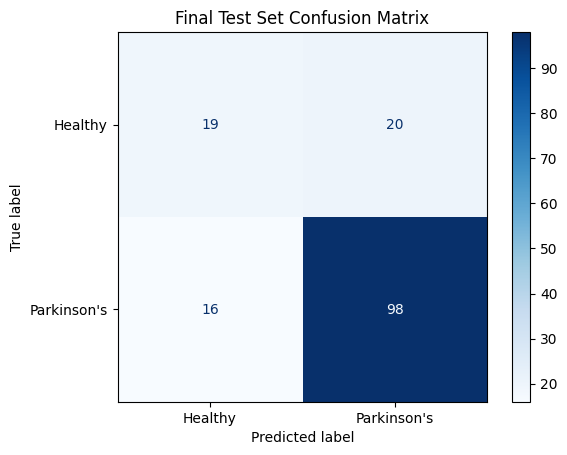

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Use the previously selected model settings and threshold.
final_weight = None if chosen_weight == "Default" else "balanced"

final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l2",
        C=0.01,
        solver="lbfgs",
        class_weight=final_weight,
        max_iter=5000,
        random_state=42
    )
)

# Fit the final model using training data only.
final_model.fit(X_train, y_train)

# Evaluate on the held-out test set.
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= chosen_threshold).astype(int)

# Calculate evaluation metrics.
test_auc = roc_auc_score(y_test, test_probabilities)
test_ap = average_precision_score(y_test, test_probabilities)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

sensitivity_test = tp / (tp + fn)
specificity_test = tn / (tn + fp)

print("FINAL HELD-OUT TEST EVALUATION")
print(f"ROC AUC: {test_auc:.3f}")
print(f"Average Precision: {test_ap:.3f}")
print(f"Threshold: {chosen_threshold:.3f}")
print(f"Sensitivity: {sensitivity_test:.3f}")
print(f"Specificity: {specificity_test:.3f}")

print("\nConfusion Matrix")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Display the confusion matrix.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Healthy", "Parkinson's"],
    cmap="Blues"
)

plt.title("Final Test Set Confusion Matrix")
plt.show()

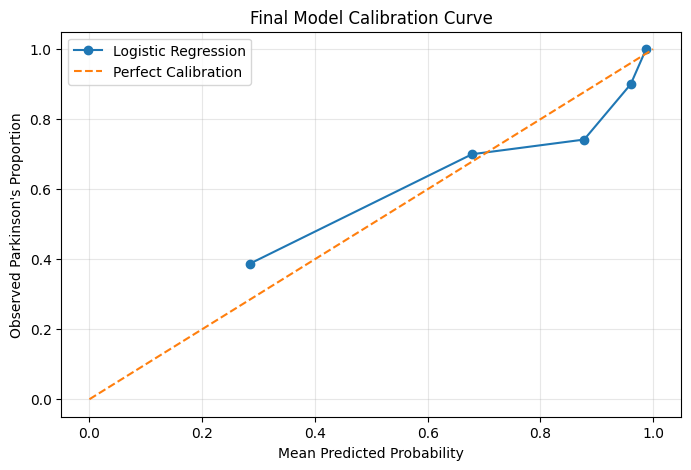

FINAL BOOTSTRAP RESULTS
Test ROC AUC: 0.819
95% Confidence Interval: [0.691, 0.919]
Valid bootstrap samples: 2000


In [ ]:
from sklearn.calibration import calibration_curve
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# Calibration curve using existing test predictions
prob_true, prob_pred = calibration_curve(
    y_test,
    test_probabilities,
    n_bins=5,
    strategy="quantile"
)

plt.figure(figsize=(8, 5))
plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Parkinson's Proportion")
plt.title("Final Model Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Bootstrap participants, not individual recordings
rng = np.random.default_rng(42)

test_ids = np.asarray(groups_test)
test_outcomes = np.asarray(y_test)
test_scores = np.asarray(test_probabilities)

unique_ids = np.unique(test_ids)

subject_positions = {
    sid: np.where(test_ids == sid)[0]
    for sid in unique_ids
}

bootstrap_aucs = []

for _ in range(2000):

    sampled_ids = rng.choice(
        unique_ids,
        size=len(unique_ids),
        replace=True
    )

    positions = np.concatenate([
        subject_positions[sid]
        for sid in sampled_ids
    ])

    y_sample = test_outcomes[positions]
    p_sample = test_scores[positions]

    # ROC AUC requires both classes
    if len(np.unique(y_sample)) < 2:
        continue

    bootstrap_aucs.append(
        roc_auc_score(y_sample, p_sample)
    )

lower, upper = np.percentile(
    bootstrap_aucs,
    [2.5, 97.5]
)

print("FINAL BOOTSTRAP RESULTS")
print(f"Test ROC AUC: {test_auc:.3f}")
print(f"95% Confidence Interval: [{lower:.3f}, {upper:.3f}]")
print("Valid bootstrap samples:", len(bootstrap_aucs))

13. Overall, I selected a classification threshold of .590 using cross-validation predictions from the training data, prioritizing sensitivity becasue missing potential Parkinson's disease cases is an important concern in screening. On the held-out test set, the model achieved sensitivity of .860 and specificty of .487, correctly identify 98 Parkinson's recordings while misclassifying 16 as healthy. This threshold reflects a trade-off between identifying potential cases and generating false positives with 20 healthy recordings incorrectly classified as Parkinson's disease. Class weighting changes the importance assigned to observations during model training, whereas moving the decision threshold changes how predicted probabilities are converted into classification without retraining the model.

14. The final test ROC AUC of .819 was consitent with the nested cross-validation estimate of .843, suggesting similar discriminatory performance across the two evaluation approaches. However, the 95% subject-level bootstrap confidence internal ranged from .691 to .919, indicating considerable uncertainty in the point estimate, given the limted numbr of independent test participants. The calibration curve also revealed differences between predicted probabilities and obserbed Parkinson's disease proportions across some probability ranges. Because of this, I would not present the raw predicted probabilities to clinicians as reliable clincial risk estimaes without further calibration, external validation, and assessment of the model's performance in a larger and more representative sample.